# **1. Bussines Understanding**

## **1.1 Latar Belakang**

Kesehatan mental mahasiswa dipengaruhi oleh berbagai aspek gaya hidup dan aktivitas akademik. Data ini menggambarkan hasil survei terhadap 10.000 mahasiswa yang mencakup kebiasaan sehari-hari, prestasi belajar, dan kesejahteraan mental sebagai bahan analisis berbasis data.

## **1.2 Tujuan**

Memabangun Machine Learning untuk memprediksi kesehatan mental mahasiswa

## **1.3 Masalah**

Dalam mendeteksi kesehatan mental masih menggunakan metode manual

## **1.4 Tujuan**

Memabangun Machine Learning untuk memprediksi kesehatan mental mahasiswa secara otomatis menggunakan machine learning

## **1.5 Deskripsi Kolom**

* Age : Usia Mahasiswa(18 - 24 tahun)
* Gender : Jenis Kelamin
* Department : Bidang studi mahasiswa
* CGPA : Nilai IPK mahasiswa
* Sleep_Duration : Rata - rata jam tidur
* Study_Hours : Rata-rata jam tidur per malam
* Social_Media_Hours : Rata-rata jam tidur per malam
* Physical_Activity : Rata-Rata aktivitas fisik per minggu dalam menit
* Stress_Level : Kolom target yaitu tingkat stress level 0-10

## 2.0 Data Preparation

In [15]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [16]:
df = pd.read_csv('student_lifestyle_100k.csv')

In [17]:
print('Jumlah Baris :', df.shape[0])
print('================================')
print('Jumlah Kolom :', df.shape[1])
print('================================')
print('5 Data Pertama : ', df.head())

Jumlah Baris : 100000
Jumlah Kolom : 11
5 Data Pertama :     Student_ID  Age  Gender   Department  CGPA  Sleep_Duration  Study_Hours  \
0        1001   22  Female      Science  3.50             7.3          3.3   
1        1002   20    Male  Engineering  2.72             5.5          7.2   
2        1003   20    Male      Medical  3.01             5.4          2.3   
3        1004   21    Male  Engineering  3.63             8.1          2.0   
4        1005   19    Male         Arts  3.14             6.8          2.6   

   Social_Media_Hours  Physical_Activity  Stress_Level  Depression  
0                 3.4                114             5       False  
1                 6.0                142             2       False  
2                 1.8                137             3       False  
3                 4.6                130             3       False  
4                 4.3                  4             6       False  


In [18]:
df.isnull().sum().sum()

np.int64(0)

In [19]:
df.duplicated().sum().sum()

np.int64(0)

In [20]:
print(df.info)
print(df.describe)

<bound method DataFrame.info of        Student_ID  Age  Gender   Department  CGPA  Sleep_Duration  \
0            1001   22  Female      Science  3.50             7.3   
1            1002   20    Male  Engineering  2.72             5.5   
2            1003   20    Male      Medical  3.01             5.4   
3            1004   21    Male  Engineering  3.63             8.1   
4            1005   19    Male         Arts  3.14             6.8   
...           ...  ...     ...          ...   ...             ...   
99995      100996   24  Female      Medical  2.02             7.0   
99996      100997   24    Male         Arts  2.33             5.0   
99997      100998   24  Female  Engineering  2.23             6.5   
99998      100999   19    Male  Engineering  3.61             6.1   
99999      101000   24  Female      Medical  2.10             7.9   

       Study_Hours  Social_Media_Hours  Physical_Activity  Stress_Level  \
0              3.3                 3.4                114       

## 3.0 Exploratoty Data Analyst

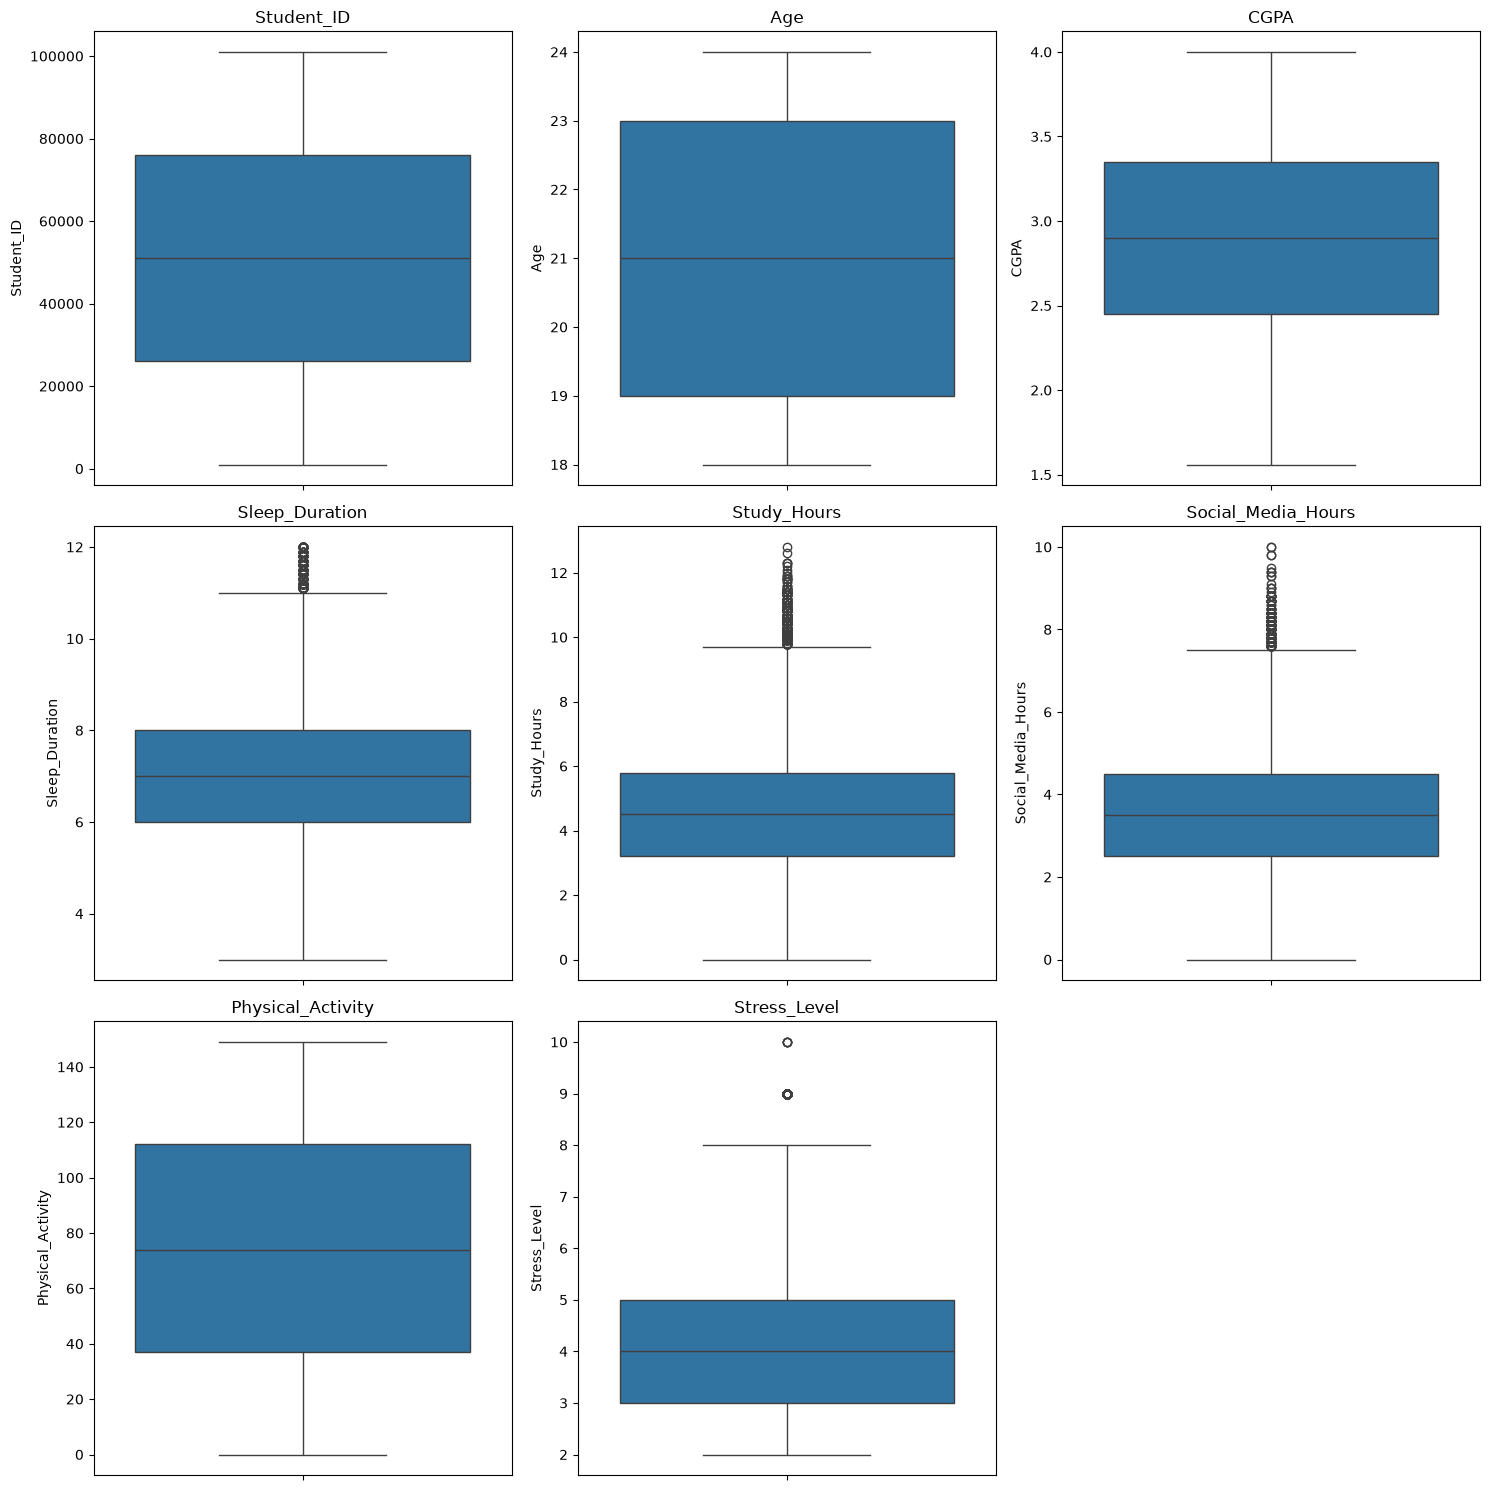

In [21]:
kolom = df.select_dtypes(include=['number'])

plt.figure(figsize=(15,15))

for i, col in enumerate(kolom, start=1):
    plt.subplot(3, 3, i)
    sns.boxplot(data=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

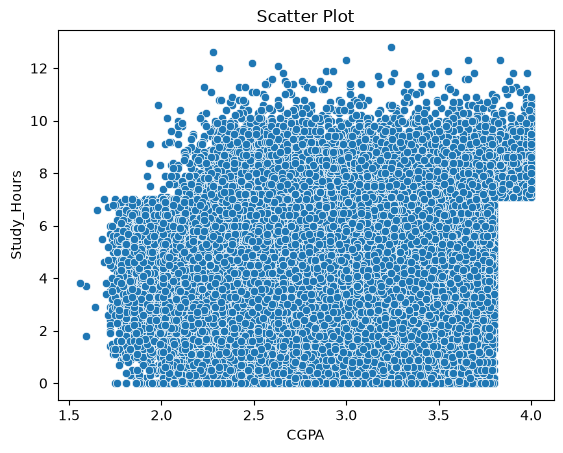

In [22]:
sns.scatterplot(data=df, x='CGPA', y='Study_Hours')
plt.title('Scatter Plot')
plt.show()

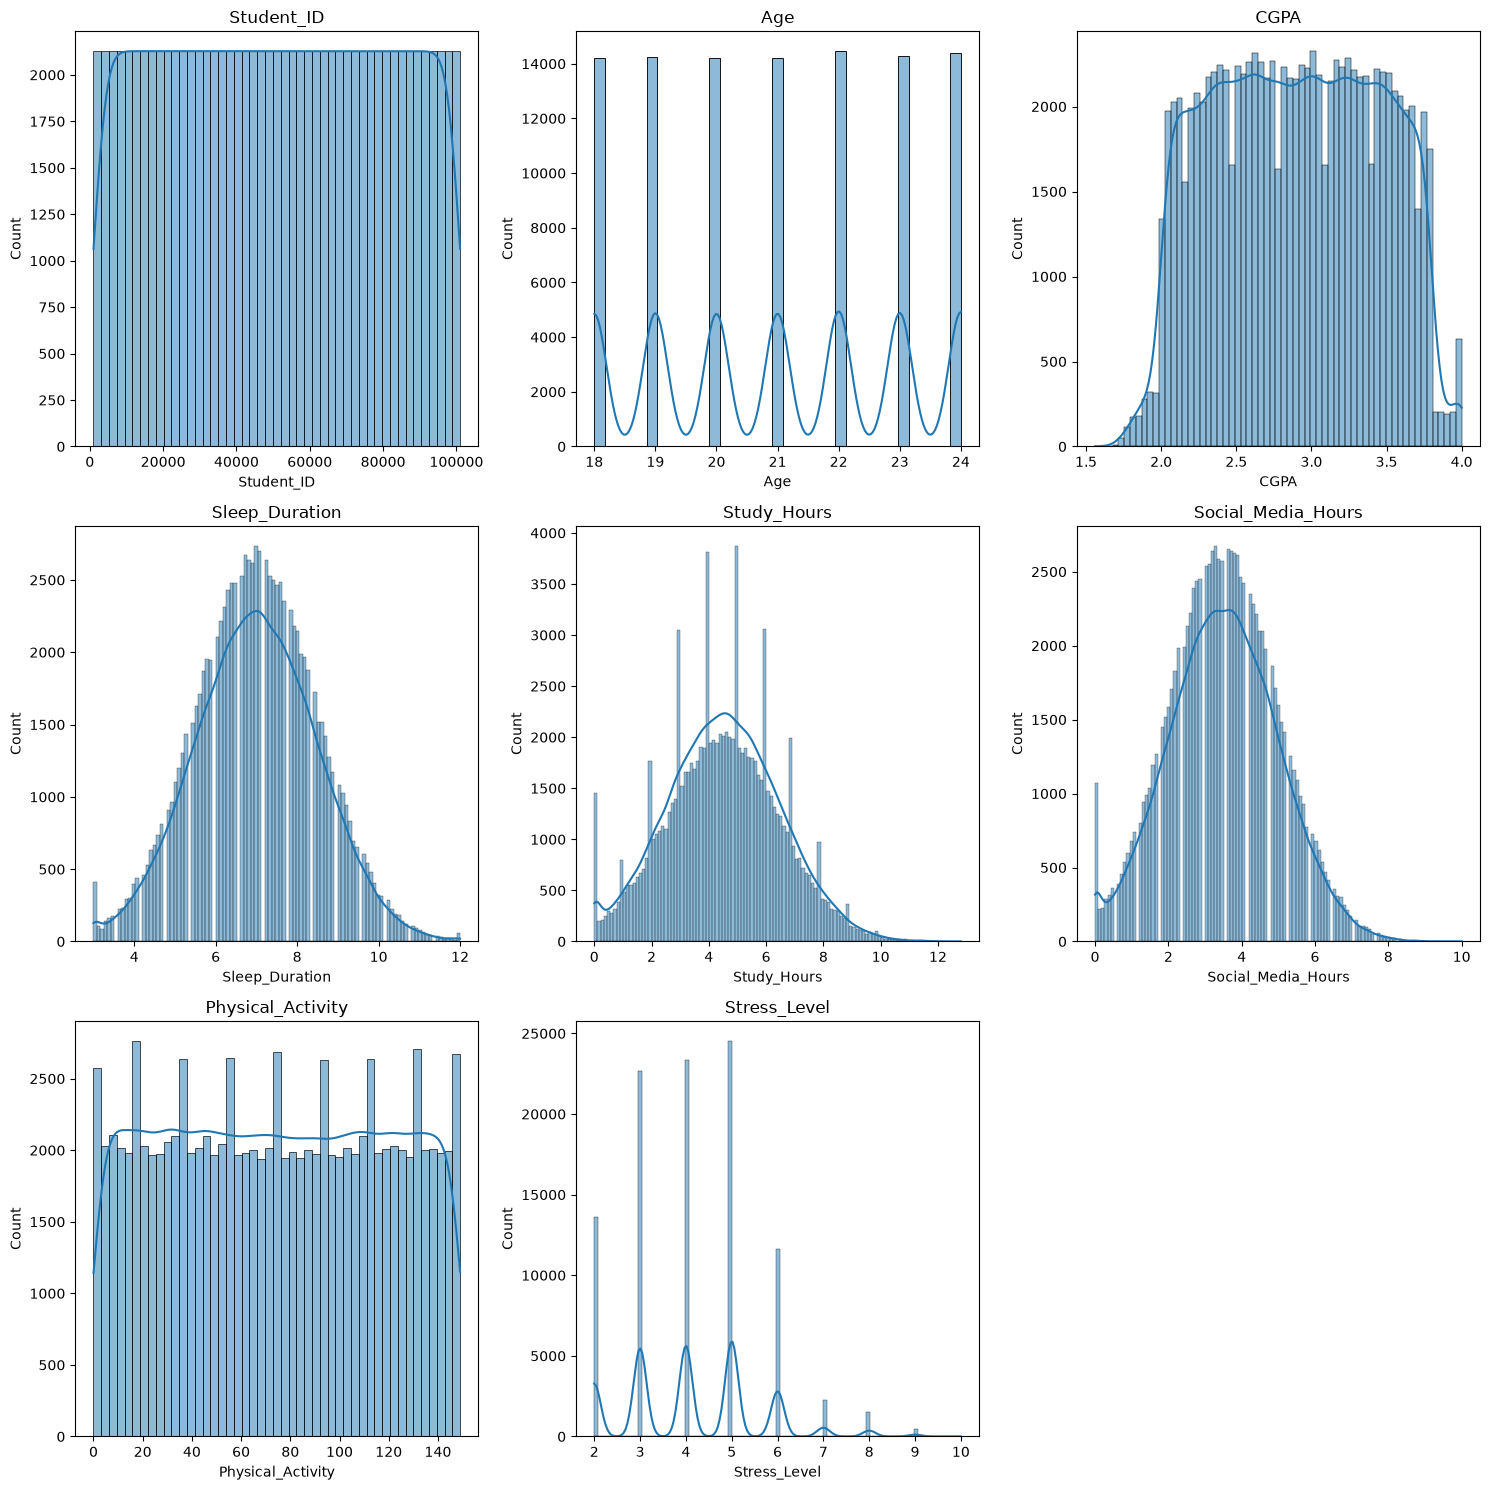

In [23]:
kolom = df.select_dtypes(include=['number'])

plt.figure(figsize=(15,15))

for i, col in enumerate(kolom, start=1):
    plt.subplot(3, 3, i)
    sns.histplot(data=df[col], kde=True)
    plt.title(col)

plt.tight_layout()
plt.show()

## 4.0 Data Preprocessing

In [24]:
df['Gender'] = df['Gender'].map({'Male': 0 , 'Female': 1})
df['Depression'] = df['Depression'].map({False: 0 , True: 1})
dept_map = {
    'Arts': 0,
    'Business': 1,
    'Engineering': 2,
    'Medical': 3,
    'Science': 4
}
df['Department'] = df['Department'].map(dept_map)

In [25]:
df.head()

,Student_ID,Age,Gender,Department,CGPA,Sleep_Duration,Study_Hours,Social_Media_Hours,Physical_Activity,Stress_Level,Depression
0,1001,22,1,4,3.50,7.3,3.3,3.4,114,5,0
1,1002,20,0,2,2.72,5.5,7.2,6.0,142,2,0
2,1003,20,0,3,3.01,5.4,2.3,1.8,137,3,0
3,1004,21,0,2,3.63,8.1,2.0,4.6,130,3,0
4,1005,19,0,0,3.14,6.8,2.6,4.3,4,6,0


In [26]:
cols = df.select_dtypes(include=['Float64', 'int64'])

Q1 = cols.quantile(0.25)
Q3 = cols.quantile(0.75)

IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier = ((cols < batas_bawah) | (cols > batas_atas)).sum()

hasil = pd.DataFrame({'Jumlah Outlier': outlier, 'Persetase Outlier': (outlier/len(df))*100}  )
hasil.sort_values('Jumlah Outlier', ascending=False)

,Jumlah Outlier,Persetase Outlier
Depression,10062,10.062
Stress_Level,478,0.478
Study_Hours,432,0.432
Sleep_Duration,369,0.369
Social_Media_Hours,328,0.328
Student_ID,0,0.000
Age,0,0.000
Gender,0,0.000
CGPA,0,0.000
Department,0,0.000


In [27]:
kolom_capping = cols.columns.drop(['Stress_Level','Depression'])
batas_bawah_cap = batas_bawah[kolom_capping]
batas_atas_cap = batas_atas[kolom_capping]

outlier_sebelum = ((df[kolom_capping] < batas_bawah_cap) | (df[kolom_capping] > batas_atas_cap)).sum()

for col in kolom_capping:
    df[col] = df[col].clip(lower=batas_bawah_cap[col], upper=batas_atas_cap[col])

outlier_sesudah = ((df[kolom_capping] < batas_bawah_cap) | (df[kolom_capping] > batas_atas_cap)).sum()

ringkasan = pd.DataFrame({
    'Outlier Sebelum': outlier_sebelum,
    'Outlier Sesudah': outlier_sesudah
})

print('Total outlier sesudah capping')

hasil = pd.DataFrame({'Jumlah Outlier': outlier_sesudah, 'Persetase Outlier': (outlier/len(df))*100}  )
hasil.sort_values('Jumlah Outlier', ascending=False)

Total outlier sesudah capping


,Jumlah Outlier,Persetase Outlier
Age,0.0,0.000
CGPA,0.0,0.000
Department,0.0,0.000
Gender,0.0,0.000
Physical_Activity,0.0,0.000
Sleep_Duration,0.0,0.369
Social_Media_Hours,0.0,0.328
Student_ID,0.0,0.000
Study_Hours,0.0,0.432
Depression,NaN,10.062


In [28]:
df.head()

,Student_ID,Age,Gender,Department,CGPA,Sleep_Duration,Study_Hours,Social_Media_Hours,Physical_Activity,Stress_Level,Depression
0,1001,22,1,4,3.50,7.3,3.3,3.4,114,5,0
1,1002,20,0,2,2.72,5.5,7.2,6.0,142,2,0
2,1003,20,0,3,3.01,5.4,2.3,1.8,137,3,0
3,1004,21,0,2,3.63,8.1,2.0,4.6,130,3,0
4,1005,19,0,0,3.14,6.8,2.6,4.3,4,6,0


In [29]:
corr_spearman = df.corr(method = 'spearman')
corr_spearman

,Student_ID,Age,Gender,Department,CGPA,Sleep_Duration,Study_Hours,Social_Media_Hours,Physical_Activity,Stress_Level,Depression
Student_ID,1.000000,0.000853,-0.002563,-0.000738,-0.001612,0.003649,0.002832,-0.001951,0.003301,-0.006293,-0.003663
Age,0.000853,1.000000,0.003107,-0.002839,0.003284,0.001617,-0.004155,-0.001174,-0.003691,0.003146,-0.007730
Gender,-0.002563,0.003107,1.000000,0.000402,0.005432,-0.003187,0.000062,-0.000941,-0.004272,-0.000711,-0.004516
Department,-0.000738,-0.002839,0.000402,1.000000,-0.002987,0.000523,-0.003358,0.002301,-0.006957,0.003145,-0.002987
CGPA,-0.001612,0.003284,0.005432,-0.002987,1.000000,0.010701,0.082951,-0.078449,0.004595,-0.009744,-0.179578
Sleep_Duration,0.003649,0.001617,-0.003187,0.000523,0.010701,1.000000,0.002589,-0.003108,0.003462,-0.201895,-0.047457
Study_Hours,0.002832,-0.004155,0.000062,-0.003358,0.082951,0.002589,1.000000,0.006662,-0.000929,0.005446,-0.014323
Social_Media_Hours,-0.001951,-0.001174,-0.000941,0.002301,-0.078449,-0.003108,0.006662,1.000000,-0.004596,0.002176,0.017077
Physical_Activity,0.003301,-0.003691,-0.004272,-0.006957,0.004595,0.003462,-0.000929,-0.004596,1.000000,-0.296217,-0.013944
Stress_Level,-0.006293,0.003146,-0.000711,0.003145,-0.009744,-0.201895,0.005446,0.002176,-0.296217,1.000000,0.050901


<Axes: >

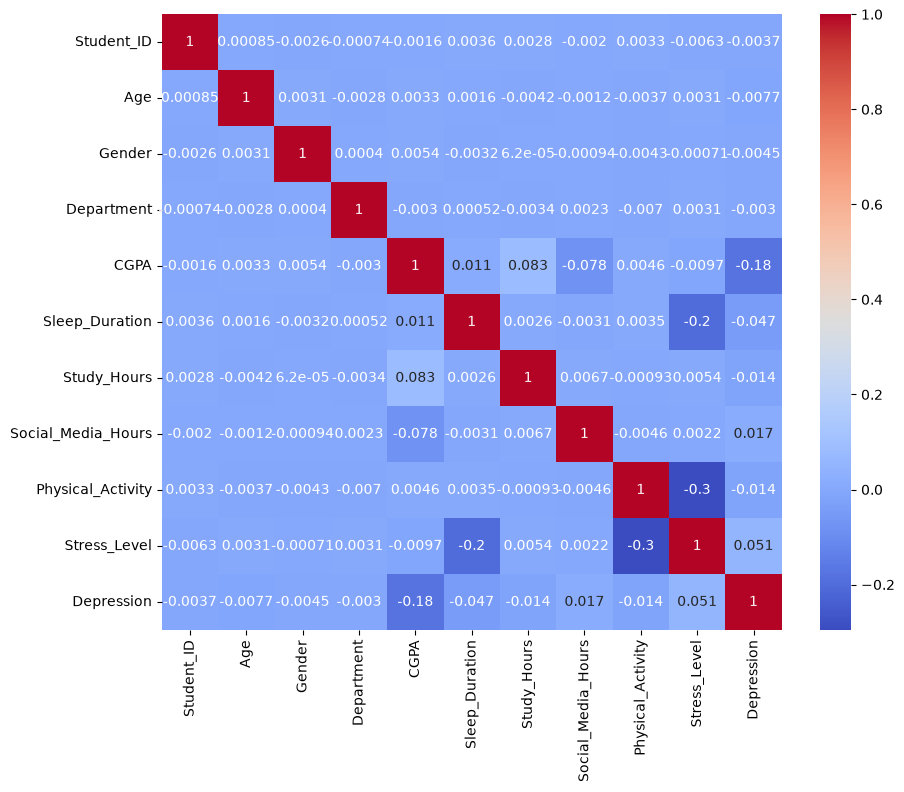

In [30]:
plt.figure(figsize=(10,8))

sns.heatmap(corr_spearman, cmap='coolwarm', fmt=".2g", annot=True)

In [31]:
X = df.drop(columns=['Depression','Stress_Level','Student_ID'])
y = df['Stress_Level']

In [32]:
cek_skala = pd.DataFrame ({
    'min': X.min(),
    'max': X.max(),
    'rentang' : X.max() - X.min(),
    'std': X.std(),
    'mean': X.mean()
})
cek_skala

,min,max,rentang,std,mean
Age,18.00,24.0,6.00,2.000382,21.009010
Gender,0.00,1.0,1.00,0.500001,0.498800
Department,0.00,4.0,4.00,1.414749,2.002000
CGPA,1.56,4.0,2.44,0.532240,2.898316
Sleep_Duration,3.00,11.0,8.00,1.493435,6.994622
Study_Hours,0.00,9.7,9.70,1.967261,4.506513
Social_Media_Hours,0.00,7.5,7.50,1.481769,3.501589
Physical_Activity,0.00,149.0,149.00,43.366963,74.353180


In [33]:
def split_data(X,y,train_size=0.8,random_state=42):
    np.random.seed(random_state)
    idx = np.random.permutation(len(X))
    split_ratio = int(train_size * len(X))

    X_train, X_test = X.iloc[idx[:split_ratio]] , X.iloc[idx[split_ratio:]]
    y_train, y_test = y.iloc[idx[:split_ratio]] , y.iloc[idx[split_ratio:]]

    return X_train,X_test, y_train, y_test


## 5.0 Modeling

In [34]:
X_train , X_test , y_train , y_test = split_data(X,y)

def matriks(X):
    return np.c_[np.ones(X.shape[0]), X]

def regresi(X_train,y_train,X_test):
    mean = X_train.mean()
    std = X_train.std()
    std = np.where(std == 0,1.0,std)
    X_train_s = (X_train - mean) / std
    X_test_s = (X_test - mean) / std
    
    X_train_b = matriks(X_train_s)
    X_test_b = matriks(X_test_s)

    parameter_b = np.linalg.inv(X_train_b.T @ X_train_b) @ X_train_b.T @ y_train
    y_pred = X_test_b @ parameter_b
    y_pred_train = X_train_b @ parameter_b

    return parameter_b , y_pred, y_pred_train

parameter_b , y_pred, y_pred_train = regresi(X_train,y_train,X_test)

## 6.0 Evaluasi

In [35]:
error_test = y_test.values - np.array(y_pred)
error_train = y_train - y_pred_train

rss = np.sum((error_test)**2)
tss = np.sum((y_test.values - y_test.values.mean())**2)

rss_tr = np.sum((error_train)**2)
tss_tr = np.sum((y_train - y_train.mean())**2)

r2_test = 1 - rss / tss
r2_train = 1 - rss_tr / tss_tr

selisih = r2_test - r2_train

print(f"r2 untuk test adalah {r2_test * 100}")
print(f"r2 untuk train adalah {r2_train * 100}")
print(f"selisih nya adalah {selisih * 100}")

r2 untuk test adalah 17.03062116112868
r2 untuk train adalah 16.628639389837296
selisih nya adalah 0.401981771291382


In [36]:
mse = np.mean((error_test)**2)
print(mse)

1.6956893993408242


In [37]:
mae = np.mean(np.abs(error_test))
print(mae)

1.089399349933365


In [38]:
rmse = np.sqrt(mse)
print(rmse)

1.3021863919350503


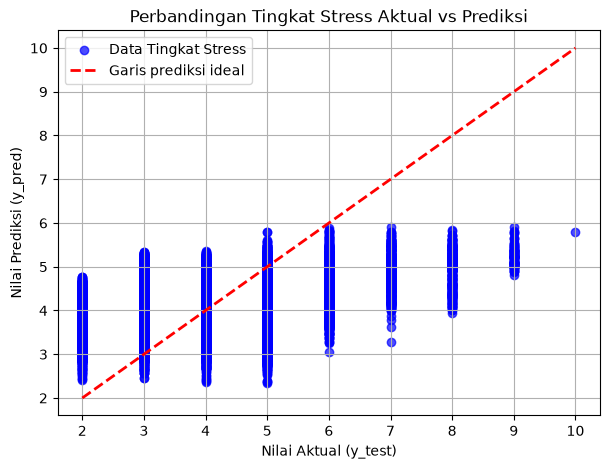

In [39]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test.values, y_pred, color='blue', alpha=0.7, label='Data Tingkat Stress')

y_min = float(y_test.values.min())
y_max = float(y_test.values.max())

plt.plot([y_min, y_max], [y_min, y_max],
         color='red', linestyle='--', linewidth=2, label='Garis prediksi ideal')

plt.title('Perbandingan Tingkat Stress Aktual vs Prediksi', fontsize=12)
plt.xlabel('Nilai Aktual (y_test)')
plt.ylabel('Nilai Prediksi (y_pred)')
plt.legend()
plt.grid(True)
plt.show()

## 7.0 Conclution

### 7.1 Analisis Dataset

* **Ukuran Data** : Ukuran data pada dataset ini tergolong besar dengan jumlah baris 100.000 dan memiliki 11 kolom
* **Kelengkapan Data** : Pada dataset ini tidak terdapat adanya missing values maupun data duplikat
* **Outlier** : Terindikasi Adanya outlier pada 5 kolom dari 11 kolom yang ada
* **Sebaran Data** : Sebaran Data tergolong cukup normal dan skala nya cukup seimbang

### 7.2 Keputusan Preprocessing

* **Encoding**: Dilakukan encoding pada data Kategorikal dan numerikal
* **Penanganan Outlier** : Melakukan Penanganan Outlier dengan menggunakan metode capping agar nilainya tidak bergeser terlalu ekstrem
* **Scaling fitur** : Melakukan Standarisasi dikarenakan agar menyamakan skala fitur yang jomplang pada physical_activity

### 7.3 Kesimpulan Algortima

* **Keputusan Pemilihan:** Memilih Multiple linear regression dikarenakan kami ingin memprediksi tingkat stress dengan lebih dari satu fitur
* **Kelebihan:**
  1. Dapat mengukur dampak dari masing-masing variabel independen(x) terhadap target secara bersamaan sambil mengontrol variabel lainnya.
  2. Hubungan antar variabel nya mudah di baca menggunakan regresi, dan perhitungan nya cepat dan ringan.
* **Kekurangan:**
  1. Rentan terhadap multikolinearitas dimana antar variabel independen memiliki hubungan yang kuat, sehingga akan mempengaruhi model
  2. Sensitif terhadap outlier yang bisa merusak garis prediksi
  3. beresiko overfitting jika terlalu banyak memakai fitur
* **Cara Mengatasi:**
  1. Menggunakan transformasi data atau menghapus salah satu kolom
  2. Mengamati outlier menggunakan iqr atau z score sebelum ke modeling
  3. Melakukan seleksi pada variabel menggunakan Backward elimination atau foward elemination.

### 7.4 Analisis Hasil Evaluasi

* **r2**: R2 yang di dapat memanglah sangat kecil di angka 17% atau bisa di bilang underfitting tapi disini wajar di karenakan target yang ingin di prediksi bersifat skala 
* **Mae** : Namun disini Nilai MAE sebesar 1.09. Rata-rata tebakan model hanya meleset sekitar 1 poin pada skala stres 2–10, yang tergolong rendah dan wajar
* **MSE** : Nilai MSE tercatat 1.70, yang berarti model tidak menghasilkan error yang besar
* **RMSE** : Nilai RMSE tercatat 1.30, membuktikan sebaran melesetnya prediksi model stabil di kisaran 1.30 poin